# V1 multi-population field in 1D: weak forcing below onset

Four populations (E, PV, SST, VIP) with the parameters of paper Sec. 7. Set `K = 3` for the E/PV/SST variant. The notebook reproduces the coefficients printed in the paper, then runs the full field below onset and compares the late amplitude with the Sec. 6 prediction.

Each run takes about 30 s (150 s of model time at 1 ms steps).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mcn_project import plotting, presets
from mcn_project.amplitude import standing_equilibrium
from mcn_project.analysis import critical_amplitudes, dominant_mode
from mcn_project.linear import find_onset
from mcn_project.normal_form import cubic_coefficients, unit_forcing_coefficients
from mcn_project.simulate import Forcing, Wave, critical_seed, simulate

plt.rcParams["figure.dpi"] = 80

In [2]:
# ---- parameters ----
K = 4
MODEL = presets.v1(K)            # edit numbers in src/mcn_project/presets.py
KAPPA_RANGE = (0.0, 1.0)         # J = kappa G
EPS, MU = 0.02, -1.0             # kappa = kappa_c + MU * EPS**2
PEAKS = dict(temporal=3.0, spatial=8.0, combined=(3.0, 2.0))  # cosine peaks, units of EPS**2
N, DT, T_END, SAVE_EVERY = 64, 1.0, 150_000.0, 10              # time in ms
SEED, NOISE = 0.02, 1e-4         # initial critical-mode size and noise, units of EPS

## 1. Onset and amplitude coefficients

For `K = 4` these equal eqs. (v1-onset-values) and (v1-computed-coefficients) of the paper.

In [3]:
onset = find_onset(MODEL, dim=1, kappa_range=KAPPA_RANGE)
nf = cubic_coefficients(MODEL, onset)
eta_t1, eta_x1 = unit_forcing_coefficients(MODEL, onset)
print(f"kappa_c = {onset.kappa:.10f},  k0 = {onset.k0:g},  omega0 = {onset.omega0:.6f}")
print(f"alpha = {nf.alpha:.6f}\nb     = {nf.b:.6f}\nc     = {nf.c:.6f}")
print(f"eta_t^(1) = {eta_t1:.6f},  eta_x^(1) = {eta_x1:.6f}   (cosine peak 1 on drive {MODEL.drive})")
print(f"temporal threshold |mu alpha| / |eta_t^(1)| = {abs(MU * nf.alpha) / abs(eta_t1):.4f}")
print("unforced preference (Re c < Re b means traveling):", "traveling" if nf.c.real < nf.b.real else "standing")
print(f"f0 = {1000 * onset.frequency:.4f} Hz, wavelength = {MODEL.length / onset.k0 * 0.1:.3f} mm")

kappa_c = 0.7491489065,  k0 = 3,  omega0 = 0.082986
alpha = 0.088058+0.064381j
b     = -6.706479+9.069454j
c     = -6.961796+8.999612j
eta_t^(1) = 0.055509-0.029075j,  eta_x^(1) = 0.018902+0.046191j   (cosine peak 1 on drive [1. 1. 0. 0.])
temporal threshold |mu alpha| / |eta_t^(1)| = 1.7408
unforced preference (Re c < Re b means traveling): traveling
f0 = 13.2077 Hz, wavelength = 1.433 mm


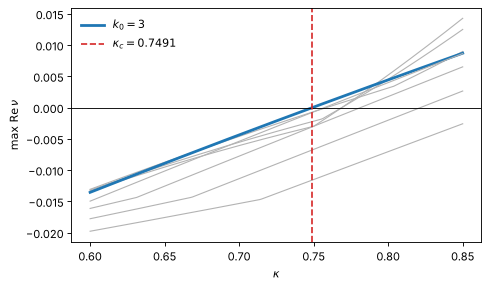

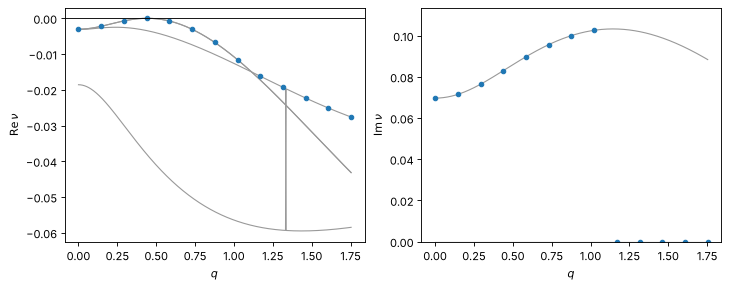

In [4]:
plotting.mode_growth(MODEL, np.linspace(0.6, 0.85, 201), range(8), onset);
plotting.dispersion(MODEL, onset.kappa, dim=1);

## 2. Forcing below onset

In [5]:
def run_case(name, waves, u0):
    return simulate(MODEL, onset.kappa + MU * EPS**2, Forcing(tuple(waves)), n=N, dt=DT,
                    t_end=T_END, save_every=SAVE_EVERY, u0=u0)

def prediction(dt=0.0, dx=0.0):
    """Standing equilibrium of Sec. 6 for cosine peaks dt, dx (units of EPS^2)."""
    eq = standing_equilibrium(MU * nf.alpha, nf.b, nf.c, dt * eta_t1, dx * eta_x1)
    return (np.nan, None) if eq is None else (EPS * np.sqrt(eq["rho"]), eq["stable"])

seed = critical_seed(MODEL, onset, SEED * EPS, n=N) + NOISE * EPS * np.random.default_rng(0).standard_normal((MODEL.K, N))
w0, k0 = onset.omega0, round(onset.k0)
cases = {
    "none": [],
    "temporal 2w0": [Wave(PEAKS["temporal"] * EPS**2, (), 2 * w0)],
    "spatial 2k0": [Wave(PEAKS["spatial"] * EPS**2, (2 * k0,))],
    "combined": [Wave(PEAKS["combined"][0] * EPS**2, (), 2 * w0), Wave(PEAKS["combined"][1] * EPS**2, (2 * k0,))],
    "detuned temporal 1.5w0": [Wave(PEAKS["temporal"] * EPS**2, (), 1.5 * w0)],
    "detuned spatial 3k0": [Wave(PEAKS["spatial"] * EPS**2, (3 * k0,))],
}
predicted = {"none": (0.0, None), "temporal 2w0": prediction(dt=PEAKS["temporal"]),
             "spatial 2k0": (np.nan, None), "combined": prediction(*PEAKS["combined"]),
             "detuned temporal 1.5w0": (0.0, None), "detuned spatial 3k0": (0.0, None)}
runs = {name: run_case(name, waves, seed) for name, waves in cases.items()}

In [6]:
print(f"{'case':24s} {'mean|A| late':>13s} {'mean|B| late':>13s} {'theory eps*sqrt(rho*)':>22s}  stable  mode")
for name, run in runs.items():
    A, B = critical_amplitudes(run, onset)
    late = run.t > 0.9 * run.t[-1]
    theory, stable = predicted[name]
    mode = dominant_mode(run.u[late, 0])
    print(f"{name:24s} {abs(A[late]).mean():13.3e} {abs(B[late]).mean():13.3e} {theory:22.3e}  {str(stable):6s}  {mode}")

case                      mean|A| late  mean|B| late  theory eps*sqrt(rho*)  stable  mode


none                         1.329e-06     7.107e-09              0.000e+00  None    (3,)
temporal 2w0                 1.594e-03     1.594e-03              1.635e-03  True    (3,)
spatial 2k0                  1.326e-03     1.326e-03                    nan  None    (3,)
combined                     1.493e-03     1.503e-03              1.538e-03  True    (3,)


detuned temporal 1.5w0       4.578e-07     3.532e-09              0.000e+00  None    (3,)
detuned spatial 3k0          1.623e-09     8.443e-12              0.000e+00  None    (9,)


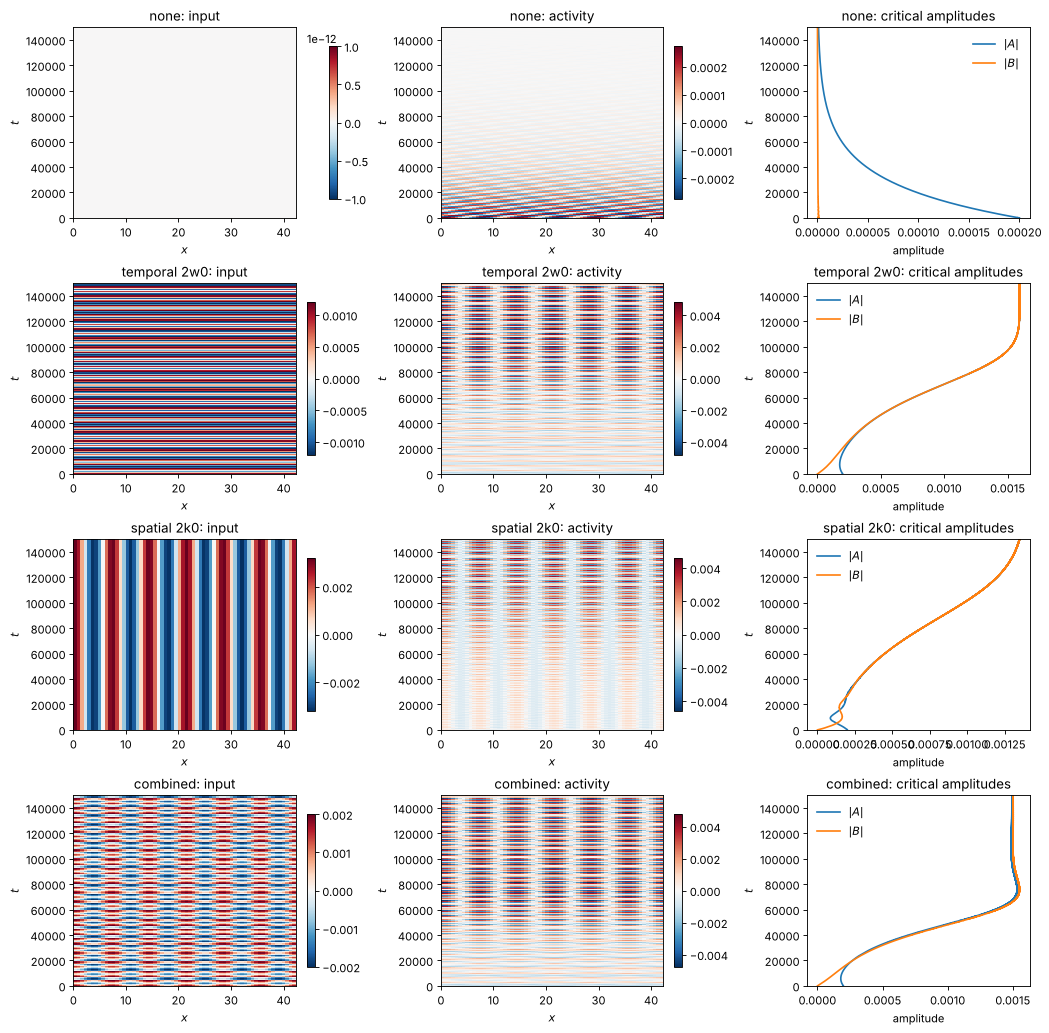

In [7]:
names = list(runs)
plotting.spacetime([runs[k] for k in names[:4]], names[:4], onset);